In [ ]:

# CELL 1: Install and Import Required Libraries

!pip install -q xgboost lightgbm catboost

# Basic libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Preprocessing
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV
)

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer

# Feature selection
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SelectFromModel

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# Boosting algorithms
from sklearn.ensemble import (
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)

print("All libraries imported successfully!")
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Goal 1 implementation environment is ready.")


All libraries imported successfully!
NumPy version: 2.1.3
Pandas version: 2.2.3
Goal 1 implementation environment is ready.


In [ ]:

# CELL 2: Fast Dataset Upload

from google.colab import files
import pandas as pd
import io

uploaded = files.upload()

filename = list(uploaded.keys())[0]

df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head(5))


Saving HR_comma_sep.csv to HR_comma_sep.csv
Dataset loaded successfully!
Shape: (14999, 10)
Columns: ['satisfaction_level', 'last_evaluation', 'number_project', 'average_montly_hours', 'time_spend_company', 'Work_accident', 'left', 'promotion_last_5years', 'sales', 'salary']


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


In [ ]:

# CELL 3: Data Inspection and Preprocessing

# 1. Check missing values
print("Missing Values:")
print(df.isnull().sum())

# 2. Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# 3. Remove duplicate records if present
df = df.drop_duplicates().reset_index(drop=True)

# 4. Display dataset shape after cleaning
print("\nShape after removing duplicates:", df.shape)

# 5. Target distribution
print("\nEmployee Attrition Distribution:")
print(df['left'].value_counts())

# 6. Target percentage
print("\nTarget Percentage:")
print((df['left'].value_counts(normalize=True) * 100).round(2))

# 7. Separate features and target
X = df.drop('left', axis=1)
y = df['left']

# 8. Convert categorical variables using One-Hot Encoding
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("\nProcessed Feature Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nFinal Feature Names:")
print(X.columns.tolist())

print("\nPreprocessing completed successfully!")


Missing Values:
satisfaction_level       0
last_evaluation          0
number_project           0
average_montly_hours     0
time_spend_company       0
Work_accident            0
left                     0
promotion_last_5years    0
sales                    0
salary                   0
dtype: int64

Duplicate Records: 3008

Shape after removing duplicates: (11991, 10)

Employee Attrition Distribution:
left
0    10000
1     1991
Name: count, dtype: int64

Target Percentage:
left
0    83.4
1    16.6
Name: proportion, dtype: float64

Processed Feature Shape: (11991, 18)
Target Shape: (11991,)

Final Feature Names:
['satisfaction_level', 'last_evaluation', 'number_project', 'average_montly_hours', 'time_spend_company', 'Work_accident', 'promotion_last_5years', 'sales_RandD', 'sales_accounting', 'sales_hr', 'sales_management', 'sales_marketing', 'sales_product_mng', 'sales_sales', 'sales_support', 'sales_technical', 'salary_low', 'salary_medium']

Preprocessing completed successfully!


In [ ]:

# CELL 4: Stratified Train-Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display split information
print("TRAIN-TEST SPLIT COMPLETED")

print("\nTraining Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True).round(3))

print("\nTrain-Test split completed successfully!")


TRAIN-TEST SPLIT COMPLETED

Training Features: (9592, 18)
Testing Features: (2399, 18)

Training Target: (9592,)
Testing Target: (2399,)

Training Target Distribution:
left
0    0.834
1    0.166
Name: proportion, dtype: float64

Testing Target Distribution:
left
0    0.834
1    0.166
Name: proportion, dtype: float64

Train-Test split completed successfully!


In [ ]:

# CELL 5: Feature Scaling

from sklearn.preprocessing import StandardScaler

# Initialize scaler
scaler = StandardScaler()

# Fit only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

# Convert back to DataFrames
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns,
    index=X_test.index
)

print("FEATURE SCALING COMPLETED")

print("\nScaled Training Shape:", X_train_scaled.shape)
print("Scaled Testing Shape:", X_test_scaled.shape)

print("\nTraining Mean (first 5 features):")
print(X_train_scaled.mean().head().round(3))

print("\nTraining Standard Deviation (first 5 features):")
print(X_train_scaled.std().head().round(3))

print("\nNo data leakage: scaler fitted only on training data.")


FEATURE SCALING COMPLETED

Scaled Training Shape: (9592, 18)
Scaled Testing Shape: (2399, 18)

Training Mean (first 5 features):
satisfaction_level      0.0
last_evaluation        -0.0
number_project          0.0
average_montly_hours    0.0
time_spend_company     -0.0
dtype: float64

Training Standard Deviation (first 5 features):
satisfaction_level      1.0
last_evaluation         1.0
number_project          1.0
average_montly_hours    1.0
time_spend_company      1.0
dtype: float64

No data leakage: scaler fitted only on training data.


MUTUAL INFORMATION FEATURE RANKING


,Feature,MI_Score
0,satisfaction_level,0.204536
1,number_project,0.131950
2,average_montly_hours,0.104272
3,last_evaluation,0.070925
4,time_spend_company,0.068367
5,Work_accident,0.009613
6,salary_low,0.007553
7,salary_medium,0.006564
8,sales_support,0.006559
9,sales_marketing,0.003394


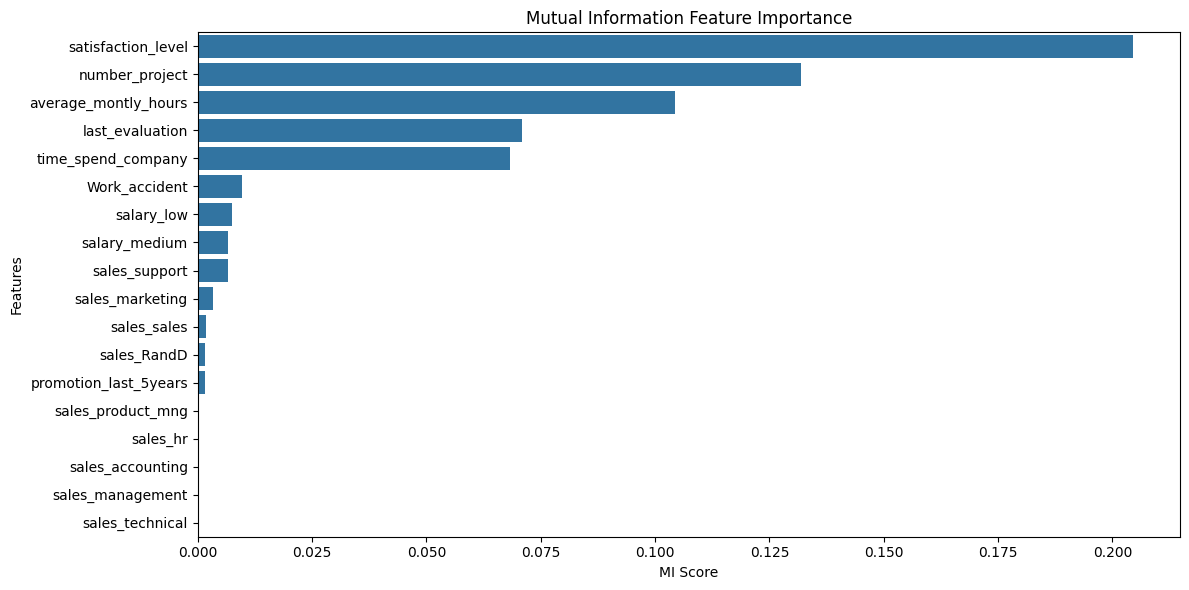


MI feature ranking completed successfully!


In [ ]:

# CELL 6: Mutual Information Feature Selection

from sklearn.feature_selection import mutual_info_classif

# Calculate MI scores using training data only
mi_scores = mutual_info_classif(
    X_train,
    y_train,
    random_state=42
)

# Create MI score table
mi_results = pd.DataFrame({
    'Feature': X_train.columns,
    'MI_Score': mi_scores
})

# Sort features by MI score
mi_results = mi_results.sort_values(
    by='MI_Score',
    ascending=False
).reset_index(drop=True)

print("MUTUAL INFORMATION FEATURE RANKING")
display(mi_results)

# Visualize MI scores
plt.figure(figsize=(12, 6))

sns.barplot(
    data=mi_results,
    x='MI_Score',
    y='Feature'
)

plt.title('Mutual Information Feature Importance')
plt.xlabel('MI Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

print("\nMI feature ranking completed successfully!")


In [ ]:

# CELL 7: Select Top MI Features

# Select top 10 features based on MI ranking
TOP_MI_FEATURES = 10

mi_selected_features = mi_results.head(TOP_MI_FEATURES)['Feature'].tolist()

# Create MI-selected training and testing datasets
X_train_mi = X_train[mi_selected_features].copy()
X_test_mi = X_test[mi_selected_features].copy()

# Display selected features
print("SELECTED MI FEATURES:")
for i, feature in enumerate(mi_selected_features, 1):
    print(f"{i}. {feature}")

print("\nMI Training Shape:", X_train_mi.shape)
print("MI Testing Shape:", X_test_mi.shape)

print("\nMI feature selection completed successfully!")


SELECTED MI FEATURES:
1. satisfaction_level
2. number_project
3. average_montly_hours
4. last_evaluation
5. time_spend_company
6. Work_accident
7. salary_low
8. salary_medium
9. sales_support
10. sales_marketing

MI Training Shape: (9592, 10)
MI Testing Shape: (2399, 10)

MI feature selection completed successfully!


In [ ]:

# CELL 8: LASSO Feature Selection

from sklearn.linear_model import LogisticRegression

# Train LASSO-based Logistic Regression
lasso_selector = LogisticRegression(
    penalty='l1',
    solver='liblinear',
    C=0.1,
    class_weight='balanced',
    max_iter=5000,
    random_state=42
)

# Fit using scaled training data only
lasso_selector.fit(X_train_scaled, y_train)

# Extract absolute feature coefficients
lasso_coefficients = np.abs(lasso_selector.coef_[0])

# Create feature importance table
lasso_results = pd.DataFrame({
    'Feature': X_train.columns,
    'LASSO_Coefficient': lasso_coefficients
})

# Sort by coefficient
lasso_results = lasso_results.sort_values(
    by='LASSO_Coefficient',
    ascending=False
).reset_index(drop=True)

# Select features with non-zero coefficients
lasso_selected_features = lasso_results.loc[
    lasso_results['LASSO_Coefficient'] > 1e-8,
    'Feature'
].tolist()

# Display results
print("LASSO FEATURE SELECTION RESULTS")
display(lasso_results)

print("\nSelected LASSO Features:")
for i, feature in enumerate(lasso_selected_features, 1):
    print(f"{i}. {feature}")

print("\nTotal selected features:", len(lasso_selected_features))

# Safety check
if len(lasso_selected_features) == 0:
    raise ValueError(
        "LASSO selected no features. Adjust regularization C."
    )

print("\nLASSO feature selection completed successfully!")


LASSO FEATURE SELECTION RESULTS


,Feature,LASSO_Coefficient
0,satisfaction_level,1.056803
1,salary_low,0.906464
2,time_spend_company,0.881129
3,salary_medium,0.707962
4,number_project,0.499006
5,Work_accident,0.476828
6,average_montly_hours,0.203592
7,last_evaluation,0.189442
8,promotion_last_5years,0.156060
9,sales_RandD,0.099793



Selected LASSO Features:
1. satisfaction_level
2. salary_low
3. time_spend_company
4. salary_medium
5. number_project
6. Work_accident
7. average_montly_hours
8. last_evaluation
9. promotion_last_5years
10. sales_RandD
11. sales_management
12. sales_product_mng
13. sales_sales
14. sales_marketing
15. sales_technical

Total selected features: 15

LASSO feature selection completed successfully!


In [ ]:

# CELL 9: Prepare LASSO Selected Datasets

# Select LASSO features
X_train_lasso = X_train[lasso_selected_features].copy()
X_test_lasso = X_test[lasso_selected_features].copy()

# Display selected features
print("LASSO SELECTED FEATURES:")

for i, feature in enumerate(lasso_selected_features, 1):
    print(f"{i}. {feature}")

# Display dataset shapes
print("\nLASSO Training Shape:", X_train_lasso.shape)
print("LASSO Testing Shape:", X_test_lasso.shape)

print("\nLASSO dataset preparation completed successfully!")


LASSO SELECTED FEATURES:
1. satisfaction_level
2. salary_low
3. time_spend_company
4. salary_medium
5. number_project
6. Work_accident
7. average_montly_hours
8. last_evaluation
9. promotion_last_5years
10. sales_RandD
11. sales_management
12. sales_product_mng
13. sales_sales
14. sales_marketing
15. sales_technical

LASSO Training Shape: (9592, 15)
LASSO Testing Shape: (2399, 15)

LASSO dataset preparation completed successfully!


In [ ]:

# CELL 10: Hybrid MI + LASSO Feature Selection

# Combine MI and LASSO selected features
hybrid_selected_features = list(dict.fromkeys(
    mi_selected_features + lasso_selected_features
))

# Create hybrid training and testing datasets
X_train_hybrid = X_train[hybrid_selected_features].copy()
X_test_hybrid = X_test[hybrid_selected_features].copy()

# Display results
print("HYBRID FEATURE SELECTION: MI + LASSO")

print("\nMI Selected Features:", len(mi_selected_features))
print("LASSO Selected Features:", len(lasso_selected_features))

print("\nHybrid Selected Features:")

for i, feature in enumerate(hybrid_selected_features, 1):
    print(f"{i}. {feature}")

print("\nTotal Hybrid Features:", len(hybrid_selected_features))

print("\nHybrid Training Shape:", X_train_hybrid.shape)
print("Hybrid Testing Shape:", X_test_hybrid.shape)

print("\nHybrid feature selection completed successfully!")


HYBRID FEATURE SELECTION: MI + LASSO

MI Selected Features: 10
LASSO Selected Features: 15

Hybrid Selected Features:
1. satisfaction_level
2. number_project
3. average_montly_hours
4. last_evaluation
5. time_spend_company
6. Work_accident
7. salary_low
8. salary_medium
9. sales_support
10. sales_marketing
11. promotion_last_5years
12. sales_RandD
13. sales_management
14. sales_product_mng
15. sales_sales
16. sales_technical

Total Hybrid Features: 16

Hybrid Training Shape: (9592, 16)
Hybrid Testing Shape: (2399, 16)

Hybrid feature selection completed successfully!


In [ ]:

# CELL 11: Boosting Algorithms with MI Features

from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score
)

# Store trained models and results
mi_models = {}
mi_results_list = []

# Define boosting algorithms
mi_boosting_models = {
    "AdaBoost": AdaBoostClassifier(
        n_estimators=200,
        learning_rate=0.5,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=-1,
        verbosity=-1,
        random_state=42,
        n_jobs=-1
    ),

    "CatBoost": CatBoostClassifier(
        iterations=300,
        depth=6,
        learning_rate=0.05,
        verbose=False,
        random_seed=42,
        thread_count=-1
    )
}

# Train and evaluate each algorithm
for name, model in mi_boosting_models.items():

    print("Training:", name)

    model.fit(X_train_mi, y_train)

    y_pred = model.predict(X_test_mi)
    y_prob = model.predict_proba(X_test_mi)[:, 1]

    mi_models[name] = model

    mi_results_list.append({
        'Feature Selection': 'MI',
        'Algorithm': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

    print(name, "completed!")

# Display MI results
mi_results_df = pd.DataFrame(mi_results_list)

print("\nMI + BOOSTING PERFORMANCE")
display(mi_results_df.round(4))

print("\nMI boosting experiments completed!")


Training: AdaBoost
AdaBoost completed!
Training: Gradient Boosting
Gradient Boosting completed!
Training: XGBoost
XGBoost completed!
Training: LightGBM
LightGBM completed!
Training: CatBoost
CatBoost completed!

MI + BOOSTING PERFORMANCE


,Feature Selection,Algorithm,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,MI,AdaBoost,0.9450,0.9030,0.7487,0.8187,0.9688
1,MI,Gradient Boosting,0.9800,0.9487,0.9296,0.9391,0.9829
2,MI,XGBoost,0.9829,0.9661,0.9296,0.9475,0.9835
3,MI,LightGBM,0.9829,0.9661,0.9296,0.9475,0.9835
4,MI,CatBoost,0.9842,0.9712,0.9322,0.9513,0.9833



MI boosting experiments completed!


In [ ]:

# CELL 12: Boosting Algorithms with LASSO Features

lasso_models = {}
lasso_results_list = []

# Define boosting algorithms
lasso_boosting_models = {
    "AdaBoost": AdaBoostClassifier(
        n_estimators=200,
        learning_rate=0.5,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        verbosity=-1,
        random_state=42,
        n_jobs=-1
    ),

    "CatBoost": CatBoostClassifier(
        iterations=300,
        depth=6,
        learning_rate=0.05,
        verbose=False,
        random_seed=42,
        thread_count=-1
    )
}

# Train and evaluate
for name, model in lasso_boosting_models.items():

    print("Training:", name)

    model.fit(X_train_lasso, y_train)

    y_pred = model.predict(X_test_lasso)
    y_prob = model.predict_proba(X_test_lasso)[:, 1]

    lasso_models[name] = model

    lasso_results_list.append({
        'Feature Selection': 'LASSO',
        'Algorithm': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

    print(name, "completed!")

# Display results
lasso_results_df = pd.DataFrame(lasso_results_list)

print("\nLASSO + BOOSTING PERFORMANCE")
display(lasso_results_df.round(4))

print("\nLASSO boosting experiments completed!")


Training: AdaBoost
AdaBoost completed!
Training: Gradient Boosting
Gradient Boosting completed!
Training: XGBoost
XGBoost completed!
Training: LightGBM
LightGBM completed!
Training: CatBoost
CatBoost completed!

LASSO + BOOSTING PERFORMANCE


,Feature Selection,Algorithm,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,LASSO,AdaBoost,0.9450,0.9030,0.7487,0.8187,0.9688
1,LASSO,Gradient Boosting,0.9800,0.9510,0.9271,0.9389,0.9832
2,LASSO,XGBoost,0.9837,0.9687,0.9322,0.9501,0.9839
3,LASSO,LightGBM,0.9846,0.9763,0.9296,0.9524,0.9815
4,LASSO,CatBoost,0.9842,0.9712,0.9322,0.9513,0.9823



LASSO boosting experiments completed!


In [ ]:

# CELL 13: Hybrid MI + LASSO with All Boosting Algorithms

hybrid_models = {}
hybrid_results_list = []

# Define boosting algorithms
hybrid_boosting_models = {
    "AdaBoost": AdaBoostClassifier(
        n_estimators=200,
        learning_rate=0.5,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        verbosity=-1,
        random_state=42,
        n_jobs=-1
    ),

    "CatBoost": CatBoostClassifier(
        iterations=300,
        depth=6,
        learning_rate=0.05,
        verbose=False,
        random_seed=42,
        thread_count=-1
    )
}

# Train and evaluate all hybrid models
for name, model in hybrid_boosting_models.items():

    print("Training:", name)

    model.fit(X_train_hybrid, y_train)

    y_pred = model.predict(X_test_hybrid)
    y_prob = model.predict_proba(X_test_hybrid)[:, 1]

    hybrid_models[name] = model

    hybrid_results_list.append({
        'Feature Selection': 'MI + LASSO Hybrid',
        'Algorithm': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

    print(name, "completed!")

# Store hybrid results
hybrid_results_df = pd.DataFrame(hybrid_results_list)

print("\nHYBRID MI + LASSO BOOSTING PERFORMANCE")
display(hybrid_results_df.round(4))

print("\nHybrid boosting experiments completed!")


Training: AdaBoost
AdaBoost completed!
Training: Gradient Boosting
Gradient Boosting completed!
Training: XGBoost
XGBoost completed!
Training: LightGBM
LightGBM completed!
Training: CatBoost
CatBoost completed!

HYBRID MI + LASSO BOOSTING PERFORMANCE


,Feature Selection,Algorithm,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,MI + LASSO Hybrid,AdaBoost,0.9450,0.9030,0.7487,0.8187,0.9688
1,MI + LASSO Hybrid,Gradient Boosting,0.9800,0.9510,0.9271,0.9389,0.9832
2,MI + LASSO Hybrid,XGBoost,0.9837,0.9687,0.9322,0.9501,0.9834
3,MI + LASSO Hybrid,LightGBM,0.9833,0.9686,0.9296,0.9487,0.9820
4,MI + LASSO Hybrid,CatBoost,0.9846,0.9738,0.9322,0.9525,0.9835



Hybrid boosting experiments completed!


In [ ]:

# CELL 14: Complete Performance Comparison

# Combine all three experiment results
all_results = pd.concat(
    [
        mi_results_df,
        lasso_results_df,
        hybrid_results_df
    ],
    ignore_index=True
)

# Display all 15 models
print("COMPLETE PERFORMANCE COMPARISON - 15 MODELS")

display(
    all_results.sort_values(
        by='Accuracy',
        ascending=False
    ).reset_index(drop=True).round(4)
)

# Find the best model for each feature selection method
print("\nBEST MODEL IN EACH FEATURE SELECTION METHOD")

best_models = all_results.loc[
    all_results.groupby('Feature Selection')['F1-Score'].idxmax()
]

display(best_models.round(4))

# Find the overall best model based on F1-score
best_model = all_results.loc[all_results['F1-Score'].idxmax()]

print("\nOVERALL BEST MODEL (BASED ON F1-SCORE)")
print(best_model)

# Find the best accuracy
best_accuracy = all_results.loc[all_results['Accuracy'].idxmax()]

print("\nHIGHEST ACCURACY MODEL")
print(best_accuracy)

print("\n15-model comparison completed successfully!")


COMPLETE PERFORMANCE COMPARISON - 15 MODELS


,Feature Selection,Algorithm,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,LASSO,LightGBM,0.9846,0.9763,0.9296,0.9524,0.9815
1,MI + LASSO Hybrid,CatBoost,0.9846,0.9738,0.9322,0.9525,0.9835
2,MI,CatBoost,0.9842,0.9712,0.9322,0.9513,0.9833
3,LASSO,CatBoost,0.9842,0.9712,0.9322,0.9513,0.9823
4,LASSO,XGBoost,0.9837,0.9687,0.9322,0.9501,0.9839
5,MI + LASSO Hybrid,XGBoost,0.9837,0.9687,0.9322,0.9501,0.9834
6,MI + LASSO Hybrid,LightGBM,0.9833,0.9686,0.9296,0.9487,0.9820
7,MI,XGBoost,0.9829,0.9661,0.9296,0.9475,0.9835
8,MI,LightGBM,0.9829,0.9661,0.9296,0.9475,0.9835
9,MI,Gradient Boosting,0.9800,0.9487,0.9296,0.9391,0.9829



BEST MODEL IN EACH FEATURE SELECTION METHOD


,Feature Selection,Algorithm,Accuracy,Precision,Recall,F1-Score,ROC-AUC
8,LASSO,LightGBM,0.9846,0.9763,0.9296,0.9524,0.9815
4,MI,CatBoost,0.9842,0.9712,0.9322,0.9513,0.9833
14,MI + LASSO Hybrid,CatBoost,0.9846,0.9738,0.9322,0.9525,0.9835



OVERALL BEST MODEL (BASED ON F1-SCORE)
Feature Selection    MI + LASSO Hybrid
Algorithm                     CatBoost
Accuracy                      0.984577
Precision                     0.973753
Recall                        0.932161
F1-Score                      0.952503
ROC-AUC                       0.983473
Name: 14, dtype: object

HIGHEST ACCURACY MODEL
Feature Selection       LASSO
Algorithm            LightGBM
Accuracy             0.984577
Precision            0.976253
Recall               0.929648
F1-Score             0.952381
ROC-AUC              0.981459
Name: 8, dtype: object

15-model comparison completed successfully!


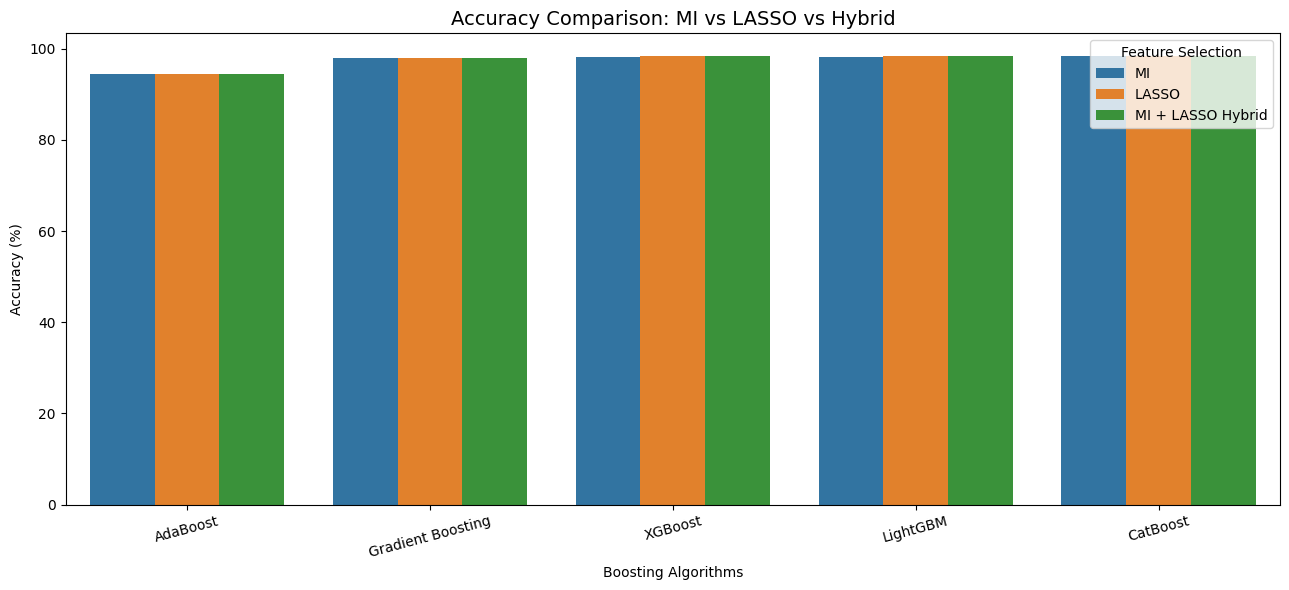

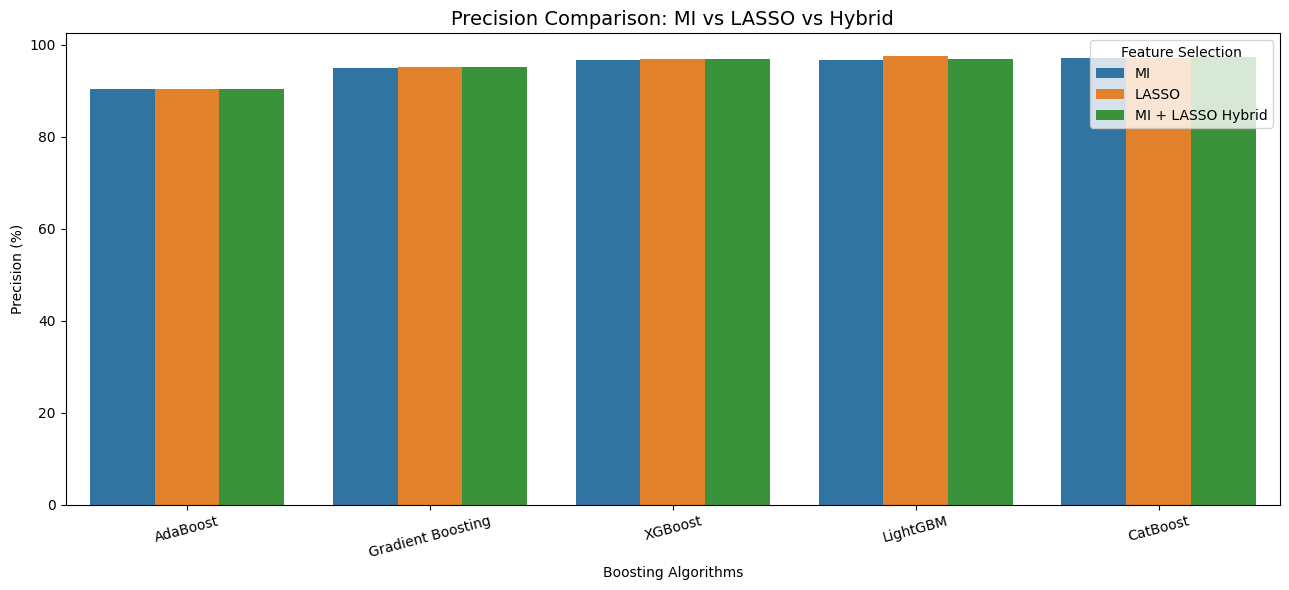

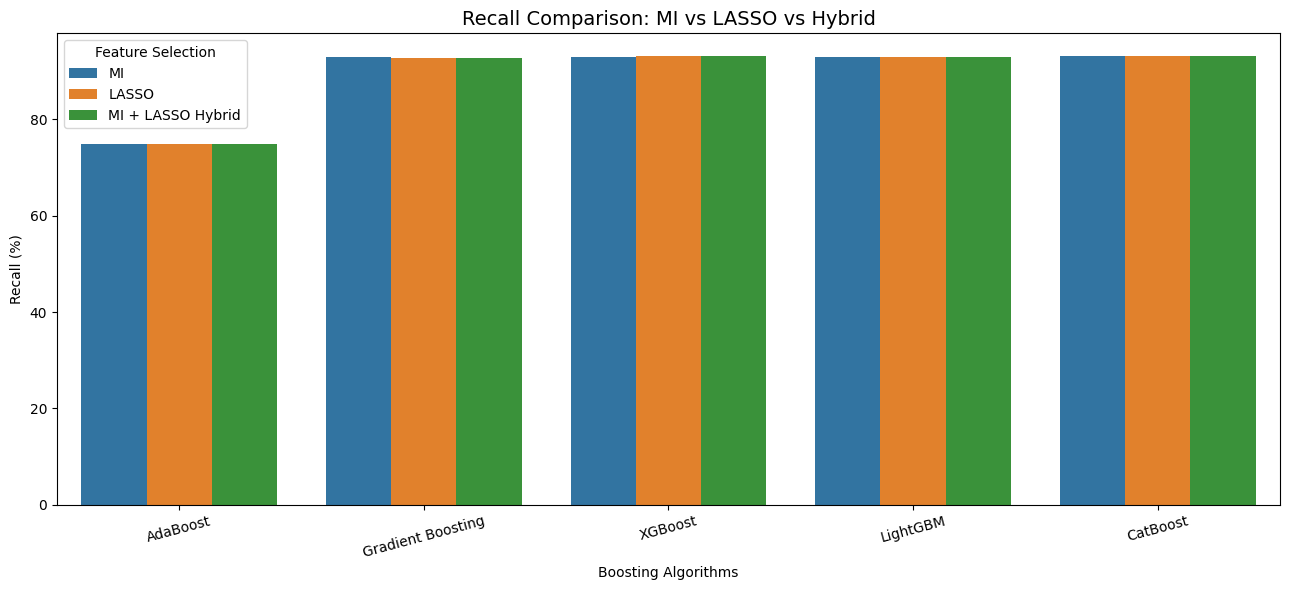

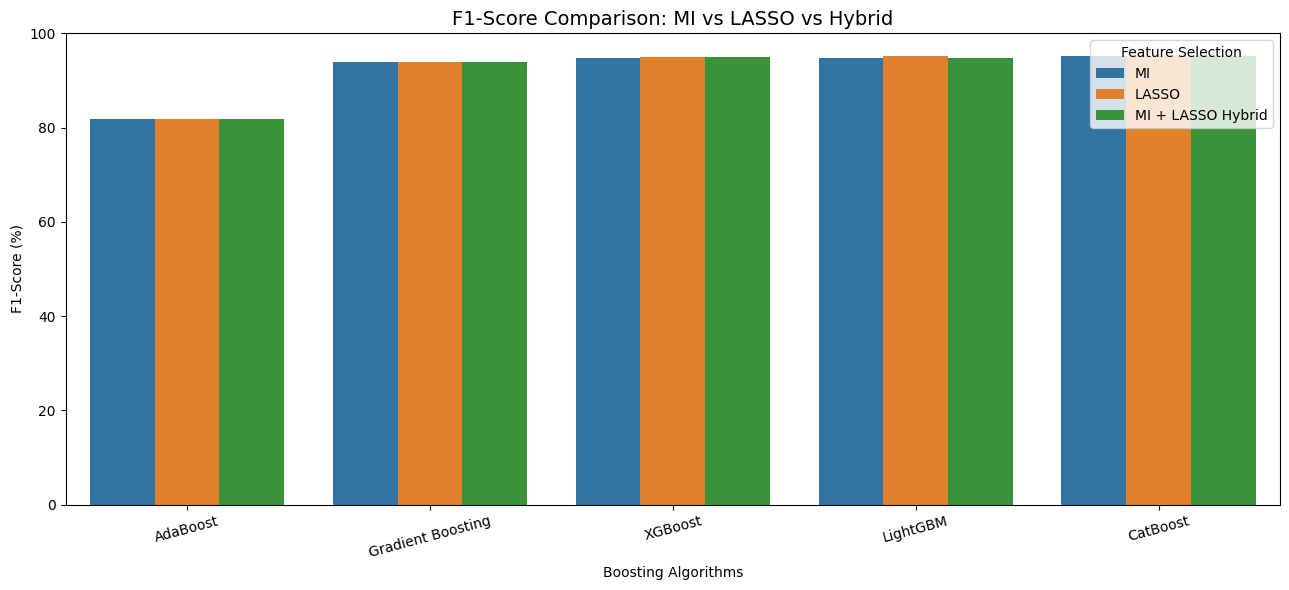

All performance comparison graphs generated!


In [ ]:

# CELL 15: Performance Comparison Visualization

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']

# Convert results into percentage format
plot_data = all_results.copy()

for metric in metrics:
    plot_data[metric] = plot_data[metric] * 100

# Generate separate comparison graphs
for metric in metrics:

    plt.figure(figsize=(13, 6))

    sns.barplot(
        data=plot_data,
        x='Algorithm',
        y=metric,
        hue='Feature Selection'
    )

    plt.title(
        f'{metric} Comparison: MI vs LASSO vs Hybrid',
        fontsize=14
    )

    plt.ylabel(f'{metric} (%)')
    plt.xlabel('Boosting Algorithms')
    plt.xticks(rotation=15)
    plt.legend(title='Feature Selection')
    plt.tight_layout()
    plt.show()

print("All performance comparison graphs generated!")


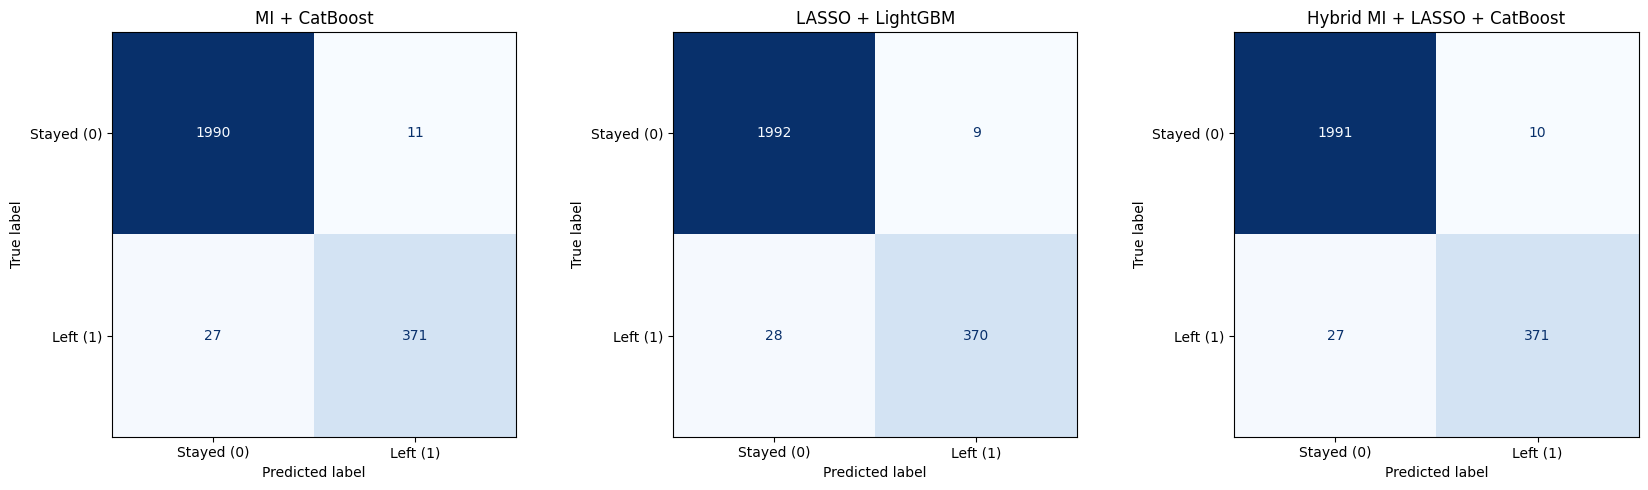

Confusion matrix comparison completed!


In [ ]:

# CELL 16: Confusion Matrix Comparison

from sklearn.metrics import ConfusionMatrixDisplay

# Select best models from each approach
best_models_to_compare = {
    "MI + CatBoost": (
        mi_models["CatBoost"],
        X_test_mi
    ),

    "LASSO + LightGBM": (
        lasso_models["LightGBM"],
        X_test_lasso
    ),

    "Hybrid MI + LASSO + CatBoost": (
        hybrid_models["CatBoost"],
        X_test_hybrid
    )
}

# Generate confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (name, (model, X_data)) in zip(
    axes, best_models_to_compare.items()
):

    y_pred = model.predict(X_data)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["Stayed (0)", "Left (1)"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

print("Confusion matrix comparison completed!")


In [ ]:

# CELL 17: Classification Reports

from sklearn.metrics import classification_report

# Best model from each feature selection method
final_models = {
    "MI + CatBoost": (
        mi_models["CatBoost"],
        X_test_mi
    ),

    "LASSO + LightGBM": (
        lasso_models["LightGBM"],
        X_test_lasso
    ),

    "Hybrid MI + LASSO + CatBoost": (
        hybrid_models["CatBoost"],
        X_test_hybrid
    )
}

# Generate classification reports
for name, (model, X_data) in final_models.items():

    print("\n" + "=" * 65)
    print(name)
    print("=" * 65)

    y_pred = model.predict(X_data)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=["Stayed", "Left"],
            digits=4
        )
    )

print("\nClassification report evaluation completed!")



MI + CatBoost
              precision    recall  f1-score   support

      Stayed     0.9866    0.9945    0.9905      2001
        Left     0.9712    0.9322    0.9513       398

    accuracy                         0.9842      2399
   macro avg     0.9789    0.9633    0.9709      2399
weighted avg     0.9841    0.9842    0.9840      2399


LASSO + LightGBM
              precision    recall  f1-score   support

      Stayed     0.9861    0.9955    0.9908      2001
        Left     0.9763    0.9296    0.9524       398

    accuracy                         0.9846      2399
   macro avg     0.9812    0.9626    0.9716      2399
weighted avg     0.9845    0.9846    0.9844      2399


Hybrid MI + LASSO + CatBoost
              precision    recall  f1-score   support

      Stayed     0.9866    0.9950    0.9908      2001
        Left     0.9738    0.9322    0.9525       398

    accuracy                         0.9846      2399
   macro avg     0.9802    0.9636    0.9716      2399
weighted av

In [ ]:

# CELL 18: Hybrid Improvement Analysis

# Find best individual and hybrid models by F1-score
best_mi = mi_results_df.loc[
    mi_results_df['F1-Score'].idxmax()
]

best_lasso = lasso_results_df.loc[
    lasso_results_df['F1-Score'].idxmax()
]

best_hybrid = hybrid_results_df.loc[
    hybrid_results_df['F1-Score'].idxmax()
]

# Create comparison table
comparison = pd.DataFrame([
    best_mi,
    best_lasso,
    best_hybrid
])

print("BEST MODEL COMPARISON")
display(comparison.round(5))

# Calculate hybrid improvement over individual methods
for metric in ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']:

    mi_improvement = (
        best_hybrid[metric] - best_mi[metric]
    ) * 100

    lasso_improvement = (
        best_hybrid[metric] - best_lasso[metric]
    ) * 100

    print(f"\n{metric}")
    print(f"Hybrid vs MI: {mi_improvement:+.4f} percentage points")
    print(f"Hybrid vs LASSO: {lasso_improvement:+.4f} percentage points")

print("\nHybrid improvement analysis completed!")


BEST MODEL COMPARISON


,Feature Selection,Algorithm,Accuracy,Precision,Recall,F1-Score,ROC-AUC
4,MI,CatBoost,0.98416,0.97120,0.93216,0.95128,0.98333
3,LASSO,LightGBM,0.98458,0.97625,0.92965,0.95238,0.98146
4,MI + LASSO Hybrid,CatBoost,0.98458,0.97375,0.93216,0.95250,0.98347



Accuracy
Hybrid vs MI: +0.0417 percentage points
Hybrid vs LASSO: +0.0000 percentage points

Precision
Hybrid vs MI: +0.2549 percentage points
Hybrid vs LASSO: -0.2500 percentage points

Recall
Hybrid vs MI: +0.0000 percentage points
Hybrid vs LASSO: +0.2513 percentage points

F1-Score
Hybrid vs MI: +0.1221 percentage points
Hybrid vs LASSO: +0.0122 percentage points

ROC-AUC
Hybrid vs MI: +0.0139 percentage points
Hybrid vs LASSO: +0.2014 percentage points

Hybrid improvement analysis completed!


In [ ]:

# CELL 19: Save Final Results

# Save all model comparison results
all_results.to_csv(
    'Goal1_All_15_Model_Results.csv',
    index=False
)

# Save selected features
feature_summary = pd.DataFrame({
    'MI_Selected_Features': pd.Series(mi_selected_features),
    'LASSO_Selected_Features': pd.Series(lasso_selected_features),
    'Hybrid_Selected_Features': pd.Series(hybrid_selected_features)
})

feature_summary.to_csv(
    'Goal1_Selected_Features.csv',
    index=False
)

# Save best model comparison
comparison.to_csv(
    'Goal1_Best_Model_Comparison.csv',
    index=False
)

print("All results saved successfully!")

# Download files
from google.colab import files

files.download('Goal1_All_15_Model_Results.csv')
files.download('Goal1_Selected_Features.csv')
files.download('Goal1_Best_Model_Comparison.csv')


All results saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# CELL 20: Final Goal 1 Summary

print("=" * 65)
print("GOAL 1: HYBRID FEATURE SELECTION WITH BOOSTING")
print("=" * 65)

print("\nDataset: HR Analytics")
print("Original Records: 14,999")
print("Cleaned Records:", len(df))
print("Total Features:", X.shape[1])

print("\nFeature Selection Methods:")
print("1. Mutual Information")
print("2. LASSO")
print("3. Hybrid MI + LASSO")

print("\nBoosting Algorithms:")
for algorithm in mi_boosting_models:
    print("-", algorithm)

print("\nTotal Models Evaluated:", len(all_results))

print("\nBEST HYBRID MODEL:")
print("Algorithm:", best_hybrid['Algorithm'])
print("Accuracy:", round(best_hybrid['Accuracy'] * 100, 2), "%")
print("Precision:", round(best_hybrid['Precision'] * 100, 2), "%")
print("Recall:", round(best_hybrid['Recall'] * 100, 2), "%")
print("F1-Score:", round(best_hybrid['F1-Score'] * 100, 2), "%")
print("ROC-AUC:", round(best_hybrid['ROC-AUC'] * 100, 2), "%")

print("\nGOAL 1 EXPERIMENTAL EXECUTION COMPLETED")
print("=" * 65)


GOAL 1: HYBRID FEATURE SELECTION WITH BOOSTING

Dataset: HR Analytics
Original Records: 14,999
Cleaned Records: 11991
Total Features: 18

Feature Selection Methods:
1. Mutual Information
2. LASSO
3. Hybrid MI + LASSO

Boosting Algorithms:
- AdaBoost
- Gradient Boosting
- XGBoost
- LightGBM
- CatBoost

Total Models Evaluated: 15

BEST HYBRID MODEL:
Algorithm: CatBoost
Accuracy: 98.46 %
Precision: 97.38 %
Recall: 93.22 %
F1-Score: 95.25 %
ROC-AUC: 98.35 %

GOAL 1 EXPERIMENTAL EXECUTION COMPLETED


In [ ]:

# CELL 21: Professional Comparison Table of All 15 Models

import pandas as pd
from IPython.display import display, HTML

# Copy all experimental results
comparison_table = all_results.copy()

# Convert metrics into percentages
metric_columns = [
    'Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'
]

for col in metric_columns:
    comparison_table[col] = comparison_table[col] * 100

# Rank models separately for each feature selection method
comparison_table['F1 Rank'] = (
    comparison_table.groupby('Feature Selection')['F1-Score']
    .rank(method='min', ascending=False)
    .astype(int)
)

# Identify the best model in each approach
comparison_table['Status'] = comparison_table['F1 Rank'].apply(
    lambda x: 'Best in Group' if x == 1 else 'Other'
)

# Arrange columns
comparison_table = comparison_table[
    [
        'Feature Selection',
        'Algorithm',
        'Accuracy',
        'Precision',
        'Recall',
        'F1-Score',
        'ROC-AUC',
        'F1 Rank',
        'Status'
    ]
]

# Sort by approach and F1-score
comparison_table = comparison_table.sort_values(
    ['Feature Selection', 'F1-Score'],
    ascending=[True, False]
).reset_index(drop=True)

# Format output
styled_table = (
    comparison_table.style
    .format({
        'Accuracy': '{:.2f}%',
        'Precision': '{:.2f}%',
        'Recall': '{:.2f}%',
        'F1-Score': '{:.2f}%',
        'ROC-AUC': '{:.2f}%'
    })
    .background_gradient(
        subset=metric_columns,
        cmap='YlGn'
    )
    .set_properties(**{
        'text-align': 'center',
        'padding': '10px',
        'border': '1px solid #dddddd'
    })
    .set_caption(
        'COMPREHENSIVE PERFORMANCE COMPARISON OF 15 MODELS'
    )
)

display(styled_table)

print("\nBest model from each feature-selection approach:")

best_per_method = (
    comparison_table[
        comparison_table['Status'] == 'Best in Group'
    ].copy()
)

display(
    best_per_method.style.format({
        'Accuracy': '{:.2f}%',
        'Precision': '{:.2f}%',
        'Recall': '{:.2f}%',
        'F1-Score': '{:.2f}%',
        'ROC-AUC': '{:.2f}%'
    })
)

# Save professional comparison
comparison_table.to_excel(
    'Goal1_Professional_Comparison.xlsx',
    index=False
)

print("\nProfessional comparison saved successfully!")


,Feature Selection,Algorithm,Accuracy,Precision,Recall,F1-Score,ROC-AUC,F1 Rank,Status
0,LASSO,LightGBM,98.46%,97.63%,92.96%,95.24%,98.15%,1,Best in Group
1,LASSO,CatBoost,98.42%,97.12%,93.22%,95.13%,98.23%,2,Other
2,LASSO,XGBoost,98.37%,96.87%,93.22%,95.01%,98.39%,3,Other
3,LASSO,Gradient Boosting,98.00%,95.10%,92.71%,93.89%,98.32%,4,Other
4,LASSO,AdaBoost,94.50%,90.30%,74.87%,81.87%,96.88%,5,Other
5,MI,CatBoost,98.42%,97.12%,93.22%,95.13%,98.33%,1,Best in Group
6,MI,XGBoost,98.29%,96.61%,92.96%,94.75%,98.35%,2,Other
7,MI,LightGBM,98.29%,96.61%,92.96%,94.75%,98.35%,2,Other
8,MI,Gradient Boosting,98.00%,94.87%,92.96%,93.91%,98.29%,4,Other
9,MI,AdaBoost,94.50%,90.30%,74.87%,81.87%,96.88%,5,Other



Best model from each feature-selection approach:


,Feature Selection,Algorithm,Accuracy,Precision,Recall,F1-Score,ROC-AUC,F1 Rank,Status
0,LASSO,LightGBM,98.46%,97.63%,92.96%,95.24%,98.15%,1,Best in Group
5,MI,CatBoost,98.42%,97.12%,93.22%,95.13%,98.33%,1,Best in Group
10,MI + LASSO Hybrid,CatBoost,98.46%,97.38%,93.22%,95.25%,98.35%,1,Best in Group



Professional comparison saved successfully!


In [ ]:

# CELL 22: Final Comparison of MI, LASSO and Hybrid

import pandas as pd
from IPython.display import display

# Create comparison using the actual best results
best_comparison = pd.DataFrame([
    best_mi,
    best_lasso,
    best_hybrid
]).reset_index(drop=True)

# Add method names
best_comparison['Method'] = [
    'MI + CatBoost',
    'LASSO + LightGBM',
    'Hybrid MI + LASSO + CatBoost'
]

# Convert metrics into percentages
metric_columns = [
    'Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'
]

for col in metric_columns:
    best_comparison[col] = best_comparison[col] * 100

# Select required columns
best_comparison = best_comparison[
    [
        'Method',
        'Accuracy',
        'Precision',
        'Recall',
        'F1-Score',
        'ROC-AUC'
    ]
].reset_index(drop=True)

# Ensure unique columns and index
best_comparison = best_comparison.loc[
    :, ~best_comparison.columns.duplicated()
]

# Display professional table
styled_comparison = (
    best_comparison.style
    .format({
        'Accuracy': '{:.3f}%',
        'Precision': '{:.3f}%',
        'Recall': '{:.3f}%',
        'F1-Score': '{:.3f}%',
        'ROC-AUC': '{:.3f}%'
    })
    .background_gradient(
        subset=metric_columns,
        cmap='YlGn'
    )
    .set_caption(
        'FINAL PERFORMANCE COMPARISON OF THREE METHODS'
    )
)

display(styled_comparison)

# Save comparison
best_comparison.to_csv(
    'Goal1_Final_Three_Methods_Comparison.csv',
    index=False
)

print("\nFinal comparison table generated successfully!")


,Method,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,MI + CatBoost,98.416%,97.120%,93.216%,95.128%,98.333%
1,LASSO + LightGBM,98.458%,97.625%,92.965%,95.238%,98.146%
2,Hybrid MI + LASSO + CatBoost,98.458%,97.375%,93.216%,95.250%,98.347%



Final comparison table generated successfully!
